# Safe Exploration: SARSA vs. Q-learning

This notebook trains and compares tabular SARSA and Q-learning in a hazardous grid world.

Run cells from top to bottom. The reusable implementation lives in `src/`.

In [1]:
import sys
from pathlib import Path

# Ensure the project root is importable when this notebook is opened from the project folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.environment import (
    ROWS, COLS, START, GOAL, HAZARDS, ACTIONS,
    N_STATES, N_ACTIONS, state_to_id, id_to_state, step, render_grid
)
from src.algorithms import epsilon_greedy, sarsa_update, q_learning_update
from src.training import train_sarsa, train_q_learning
from src.evaluation import (
    evaluate_agent, plot_learning_curves, plot_policy, print_comparison, plot_agent_trajectory
)

print("Project imports successful.")

Project imports successful.


## 1. Inspect the environment

Start: (5, 0)
Goal: (5, 5)
Hazards: [(3, 2), (3, 3), (5, 1), (5, 2), (5, 3), (5, 4)]


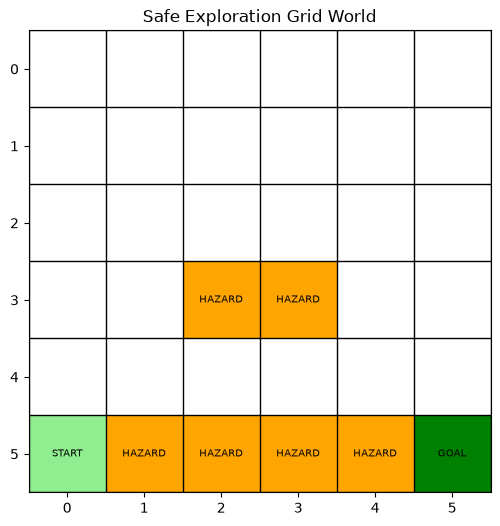

In [3]:
print("Start:", START)
print("Goal:", GOAL)
print("Hazards:", sorted(HAZARDS))
render_grid()
plt.show()

## 2. Check state indexing and environment transitions

In [4]:
assert state_to_id((5, 0)) == 30
assert id_to_state(35) == (5, 5)
assert step((5, 0), 2) == ((5, 0), -1.0, False)  # left boundary
assert step((5, 0), 3) == (START, -20.0, False)   # into cliff, reset
assert step((5, 4), 3) == (GOAL, 20.0, True)      # goal
print("Basic environment tests passed.")

Basic environment tests passed.


## 3. Understand epsilon-greedy action selection

In [5]:
Q_demo = np.zeros((N_STATES, N_ACTIONS))
Q_demo[state_to_id(START)] = [1, 5, 2, 0]
rng = np.random.default_rng(7)
print("Greedy action (epsilon=0):",
      epsilon_greedy(Q_demo, state_to_id(START), 0.0, rng))

Greedy action (epsilon=0): 1


## 4. Train both algorithms

Both agents use the same environment, learning rate, discount factor,
exploration rate, and episode limit. The seed controls each run's randomness.

In [6]:
NUM_EPISODES = 2000
ALPHA = 0.1
GAMMA = 0.95
EPSILON = 0.2
MAX_STEPS = 100
SEED = 7

Q_sarsa, history_sarsa = train_sarsa(
    num_episodes=NUM_EPISODES,
    alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON,
    max_steps=MAX_STEPS, seed=SEED
)

Q_qlearning, history_qlearning = train_q_learning(
    num_episodes=NUM_EPISODES,
    alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON,
    max_steps=MAX_STEPS, seed=SEED
)

print("Training complete.")
print("SARSA mean return, last 100 episodes:",
      history_sarsa["rewards"][-100:].mean())
print("Q-learning mean return, last 100 episodes:",
      history_qlearning["rewards"][-100:].mean())
print("SARSA hazards, last 100 episodes:",
      history_sarsa["hazards"][-100:].mean())
print("Q-learning hazards, last 100 episodes:",
      history_qlearning["hazards"][-100:].mean())

Training complete.
SARSA mean return, last 100 episodes: 2.25
Q-learning mean return, last 100 episodes: 2.75
SARSA hazards, last 100 episodes: 0.13
Q-learning hazards, last 100 episodes: 0.42


## 5. Plot training curves

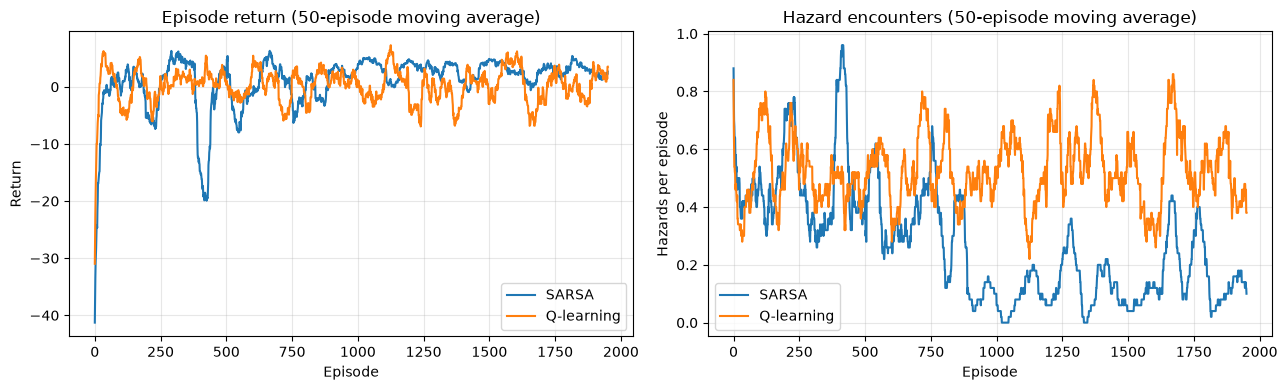

In [7]:
fig = plot_learning_curves(history_sarsa, history_qlearning, window=50)
plt.show()

## 6. Evaluate the learned greedy policies

Training includes exploration. Evaluation disables intentional exploration
and tests the learned greedy policy. Because ties can occur, evaluation uses
random tie-breaking with a fixed evaluation seed.

In [8]:
sarsa_results = evaluate_agent(
    Q_sarsa, num_tests=200, max_steps=MAX_STEPS, seed=101
)
qlearning_results = evaluate_agent(
    Q_qlearning, num_tests=200, max_steps=MAX_STEPS, seed=101
)

print_comparison(sarsa_results, qlearning_results)

Metric                                  SARSA   Q-learning
----------------------------------------------------------
Average evaluation return                8.00        14.00
Average hazards per episode              0.00         0.00
Success rate (%)                       100.00       100.00
Average steps                           13.00         7.00


## 7. Visualize learned policies

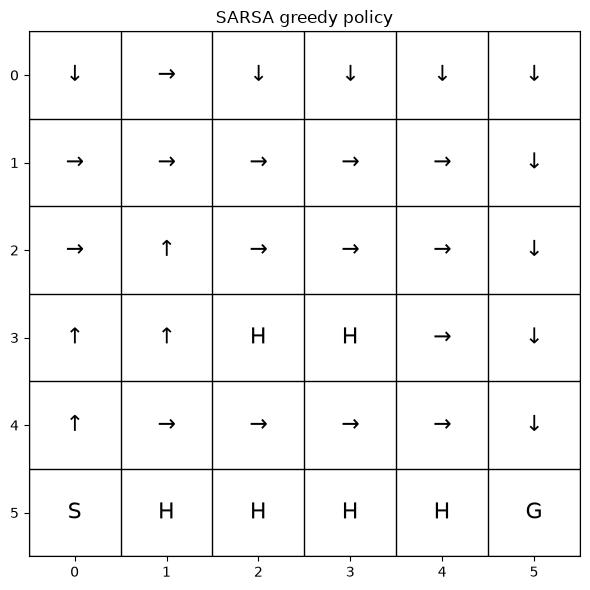

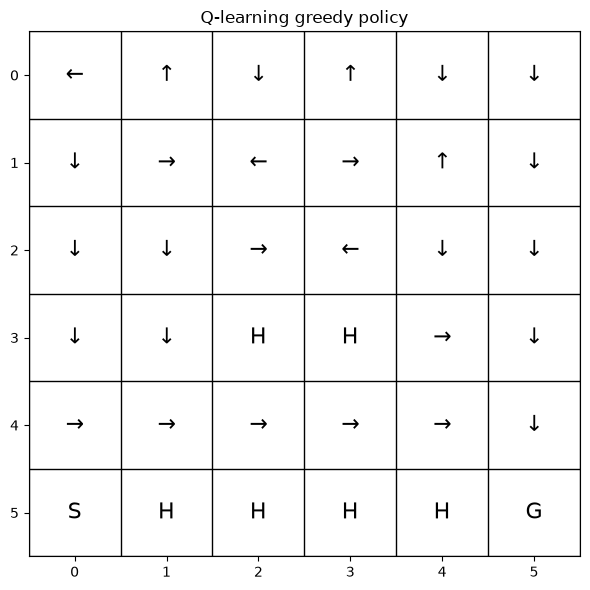

In [9]:
fig1 = plot_policy(Q_sarsa, "SARSA greedy policy")
fig2 = plot_policy(Q_qlearning, "Q-learning greedy policy")
plt.show()

Plot saved at: /Users/shweta/Documents/Safe_Exploration_RL/results/sarsa__actual_agent_trajectory.png


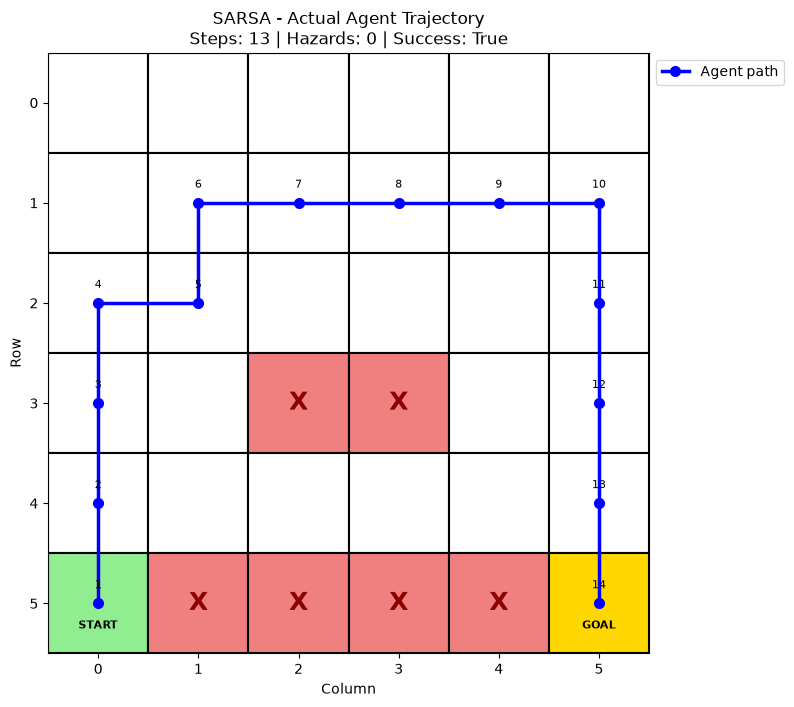

Plot saved at: /Users/shweta/Documents/Safe_Exploration_RL/results/qlearning__actual_agent_trajectory.png


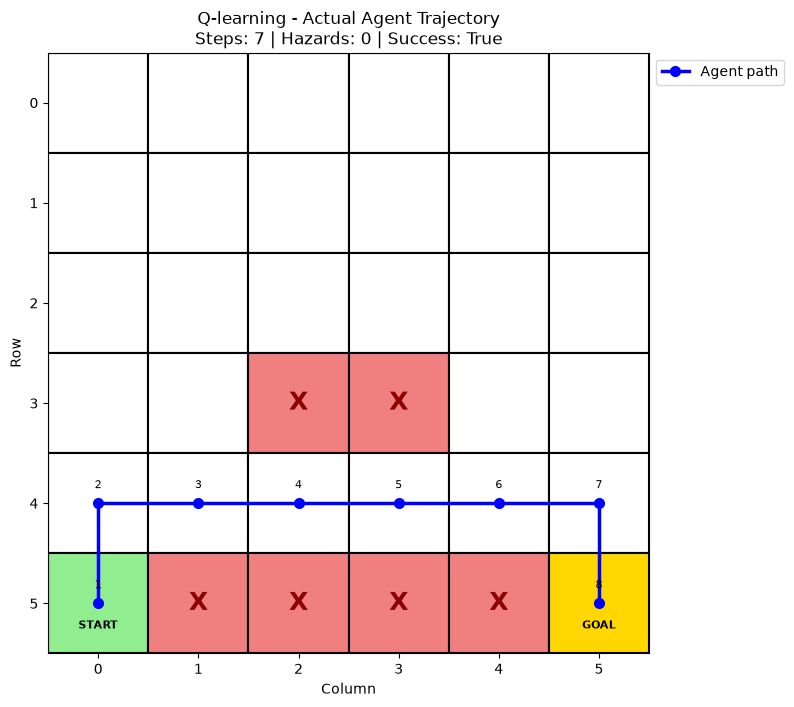

In [10]:
sarsa_path = plot_agent_trajectory(
    Q_sarsa,
    title="SARSA - Actual Agent Trajectory"
)

q_learning_path = plot_agent_trajectory(
    Q_qlearning,
    title="Q-learning - Actual Agent Trajectory"
)

## 8. Experiment with epsilon

In [11]:
# Run this after the baseline. Each run starts from a fresh Q-table.
epsilon_values = [0.05, 0.2, 0.4]
epsilon_summary = {}

for eps in epsilon_values:
    Qs, hs = train_sarsa(
        num_episodes=NUM_EPISODES, alpha=ALPHA, gamma=GAMMA,
        epsilon=eps, max_steps=MAX_STEPS, seed=SEED
    )
    Qq, hq = train_q_learning(
        num_episodes=NUM_EPISODES, alpha=ALPHA, gamma=GAMMA,
        epsilon=eps, max_steps=MAX_STEPS, seed=SEED
    )
    epsilon_summary[eps] = {
        "SARSA return": hs["rewards"][-100:].mean(),
        "Q-learning return": hq["rewards"][-100:].mean(),
        "SARSA hazards": hs["hazards"][-100:].mean(),
        "Q-learning hazards": hq["hazards"][-100:].mean(),
    }

epsilon_summary

{0.05: {'SARSA return': np.float64(12.32),
  'Q-learning return': np.float64(11.95),
  'SARSA hazards': np.float64(0.06),
  'Q-learning hazards': np.float64(0.08)},
 0.2: {'SARSA return': np.float64(2.25),
  'Q-learning return': np.float64(2.75),
  'SARSA hazards': np.float64(0.13),
  'Q-learning hazards': np.float64(0.42)},
 0.4: {'SARSA return': np.float64(-6.97),
  'Q-learning return': np.float64(-34.36),
  'SARSA hazards': np.float64(0.22),
  'Q-learning hazards': np.float64(1.85)}}